# 07 · Explainable AI with SHAP

Global and local explanations of the selected pipeline, computed on the held-out test set:

* **SHAP values** from `shap.LinearExplainer`, the exact explainer for a linear model, with a training-set background.
* **Permutation importance**, an independent check: the drop in held-out PR-AUC when a feature is shuffled.

Both describe **what the model does**. Neither says what causes attrition.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from talentscope import config
from talentscope.reporting import figures as F
F.setup()
print("TalentScope root:", ROOT.name, "| seed", config.RANDOM_SEED)

TalentScope root: TalentScope | seed 42


In [2]:
import shap
from talentscope.modeling import load_bundle
from talentscope.explainability import build_explainer, explain, aggregate_by_source, load_explanations
from talentscope.data import load_dataset, split_features_target, schema
from talentscope.preprocessing import make_split
b = load_bundle(); model = b.load_model()
df = load_dataset(); X, y = split_features_target(df)
X_train, X_test, y_train, y_test = make_split(X, y)
saved = load_explanations(b)
print("explainer:", saved["meta"]["explainer"], "| output space:", saved["meta"]["output_space"], "| rows:", saved["meta"]["rows_explained"])

explainer: linear | output space: log-odds | rows: 294


## 1. Recompute SHAP and check it against the saved values and the model

In [3]:
explainer = build_explainer(model, b.selection["model"], X_train)
ex = explain(model, explainer, X_test, b.selection["model"])
print("matches saved values:", np.allclose(ex.values, saved["shap"].values, atol=1e-8))
logit = ex.base_value + ex.values.sum(1)
print("base + sum(SHAP) reproduces predictions:", np.allclose(1 / (1 + np.exp(-logit)), model.predict_proba(X_test)[:, 1], atol=1e-8))
print(f"base value {ex.base_value:+.3f} log-odds = {1 / (1 + np.exp(-ex.base_value)):.1%}")

matches saved values: True
base + sum(SHAP) reproduces predictions: True
base value -2.478 log-odds = 7.7%


The SHAP values are additive. For each employee, the base value plus the sum of the 51 contributions equals the model's
log-odds exactly. The feature-name mapping (one-hot columns back to raw attributes) is what the aggregation below
relies on.

## 2. Global importance

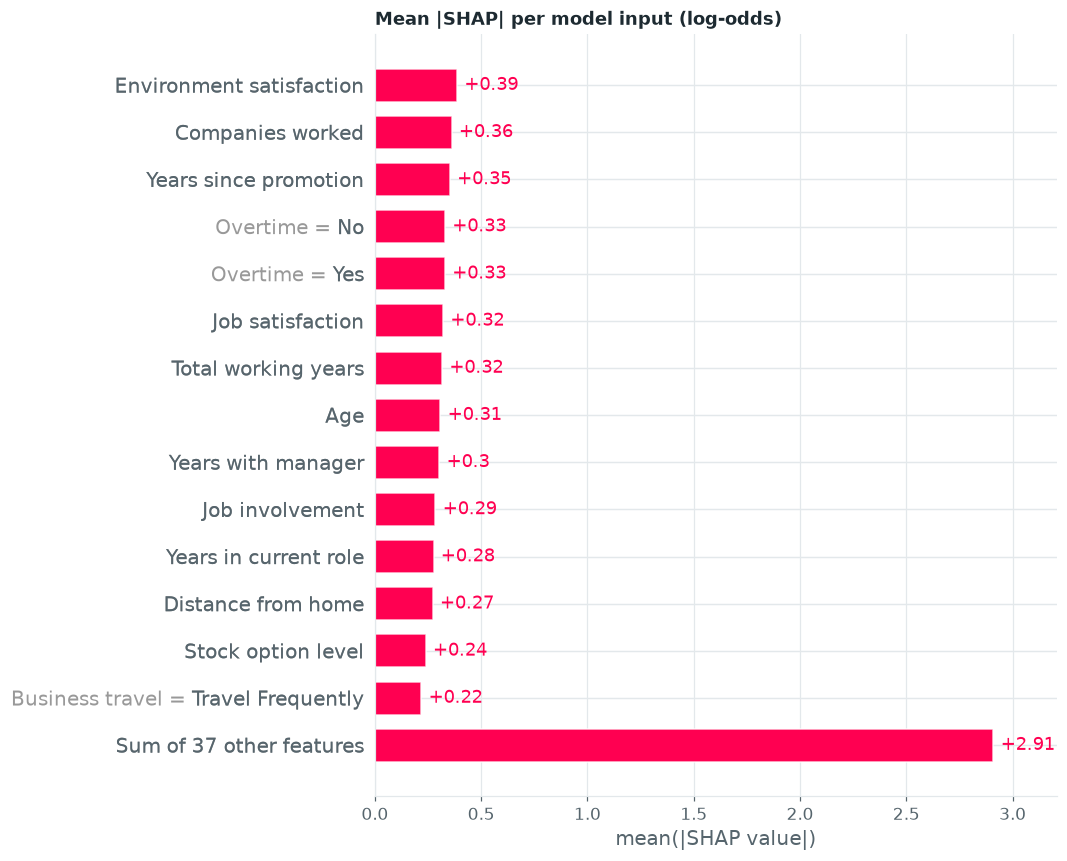

In [4]:
expl = shap.Explanation(values=ex.values, base_values=np.full(len(ex.values), ex.base_value),
                        data=ex.display_data, feature_names=ex.pretty_names)
shap.plots.bar(expl, max_display=15, show=False); plt.title("Mean |SHAP| per model input (log-odds)", loc="left"); plt.show()

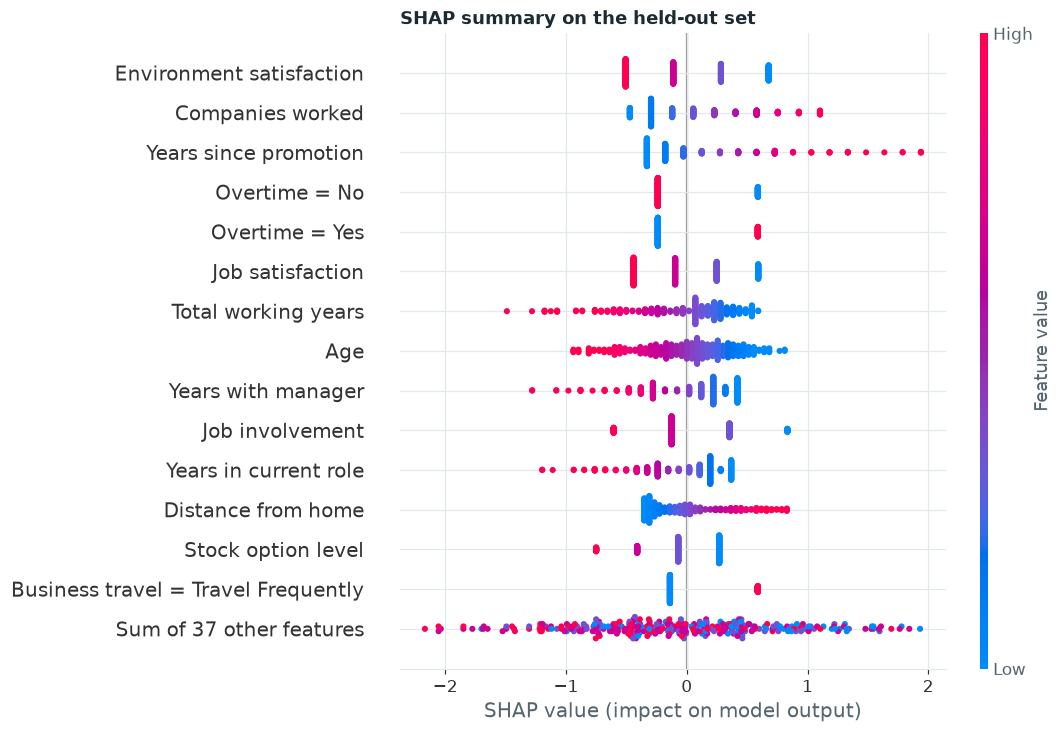

In [5]:
shap.plots.beeswarm(expl, max_display=15, show=False); plt.title("SHAP summary on the held-out set", loc="left"); plt.show()

**How to read the beeswarm.** Each dot is one test employee. Position shows how much that input moved their log-odds,
and colour shows the input's value (red is high). The model pushes risk **up** for overtime, years since last
promotion, number of previous employers, frequent travel and the Sales Representative and Laboratory Technician roles.
It pushes risk **down** for environment, job and relationship satisfaction, job involvement, total working years and
years with the current manager.

### Aggregated to the 30 raw attributes, compared with permutation importance

In [6]:
agg = aggregate_by_source(ex.values, ex.feature_names).abs().mean().sort_values(ascending=False)
perm = saved["permutation_importance"].set_index("feature")
comp = pd.DataFrame({"mean |SHAP|": agg, "SHAP rank": agg.rank(ascending=False).astype(int),
                     "permutation Δ PR-AUC": perm["importance_mean"], "perm SD": perm["importance_std"]})
comp["perm rank"] = comp["permutation Δ PR-AUC"].rank(ascending=False).astype(int)
comp = comp.sort_values("mean |SHAP|", ascending=False)
comp.index = [schema.PRETTY_NAMES.get(i, i) for i in comp.index]
from scipy.stats import spearmanr
print(f"Spearman rank agreement between the two methods: {spearmanr(comp['mean |SHAP|'], comp['permutation Δ PR-AUC']).statistic:.2f}")
comp.head(15)

Spearman rank agreement between the two methods: 0.74


,mean |SHAP|,SHAP rank,permutation Δ PR-AUC,perm SD,perm rank
Overtime,0.660,1,2.423e-01,0.030,1
Environment satisfaction,0.387,2,3.636e-02,0.025,5
Companies worked,0.361,3,5.812e-02,0.016,3
Years since promotion,0.353,4,5.484e-02,0.022,4
Job role,0.342,5,-2.540e-04,0.024,22
Job satisfaction,0.321,6,7.395e-02,0.019,2
Total working years,0.316,7,3.497e-02,0.021,6
Age,0.308,8,-5.937e-04,0.015,23
Years with manager,0.303,9,1.149e-02,0.018,13
Job involvement,0.285,10,3.225e-02,0.019,7


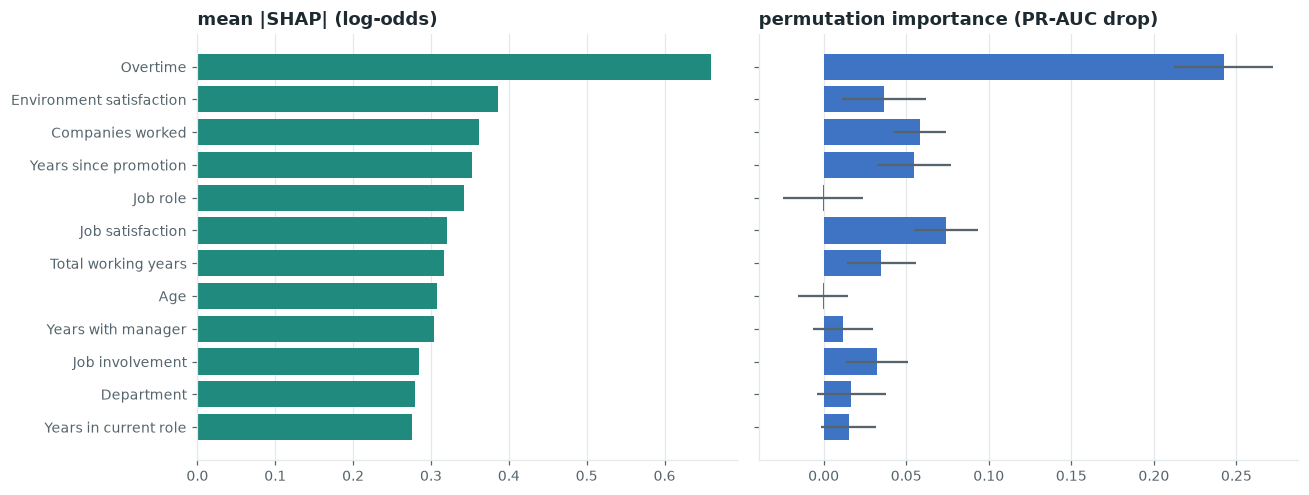

In [7]:
top = comp.head(12).iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
axes[0].barh(top.index, top["mean |SHAP|"], color=F.TEAL); axes[0].set_title("mean |SHAP| (log-odds)")
axes[1].barh(top.index, top["permutation Δ PR-AUC"], xerr=top["perm SD"], color=F.BLUE, ecolor=F.MUTED); axes[1].set_title("permutation importance (PR-AUC drop)")
for ax in axes: ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

**Agreement and disagreement**

* Both methods put **overtime** first, by a wide margin.
* Both rank job satisfaction, number of companies worked, years since promotion and environment satisfaction near the
  top.
* **Disagreements are informative.** Age, job role and the tenure counts get substantial SHAP values but small
  permutation importance. Shuffling one of a group of correlated features (age, total working years, tenure, level,
  income) costs little, because the others still carry the information. SHAP splits credit among them instead. Neither
  view is "the" importance.

## 3. Dependence: how one input's value maps to its effect

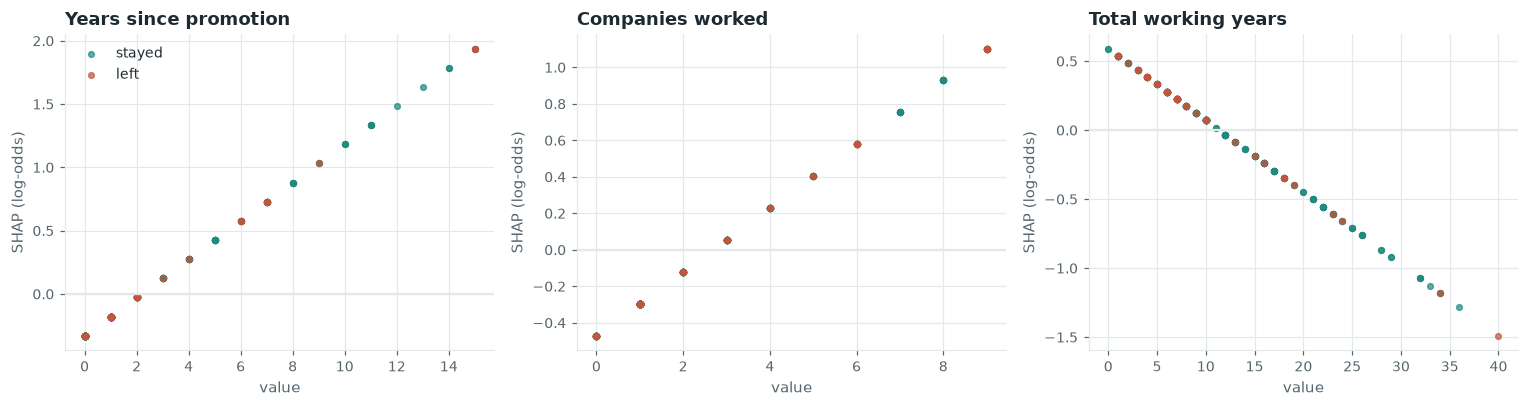

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, feat in zip(axes, ["num__YearsSinceLastPromotion", "num__NumCompaniesWorked", "num__TotalWorkingYears"]):
    j = ex.feature_names.index(feat); yy = y_test.reindex(ex.row_ids).to_numpy()
    for v, c, lab in ((0, F.TEAL, "stayed"), (1, F.CLAY, "left")):
        ax.scatter(ex.display_data[yy == v, j], ex.values[yy == v, j], s=14, color=c, alpha=0.7, label=lab)
    ax.axhline(0, color=F.GRID); ax.set_title(schema.pretty_feature(feat)); ax.set_xlabel("value"); ax.set_ylabel("SHAP (log-odds)")
axes[0].legend(); plt.tight_layout(); plt.show()

For a logistic regression each dependence plot is a straight line by construction: the effect is linear in the
standardised feature. Real effects are probably not linear. Very long time since promotion is, for example, also a
mark of long tenure. This is a known limitation of the selected model, and the price of its stability on 1,176 training
rows.

## 4. Local explanations

Employee #478 (highest predicted risk): predicted 96%, actually left


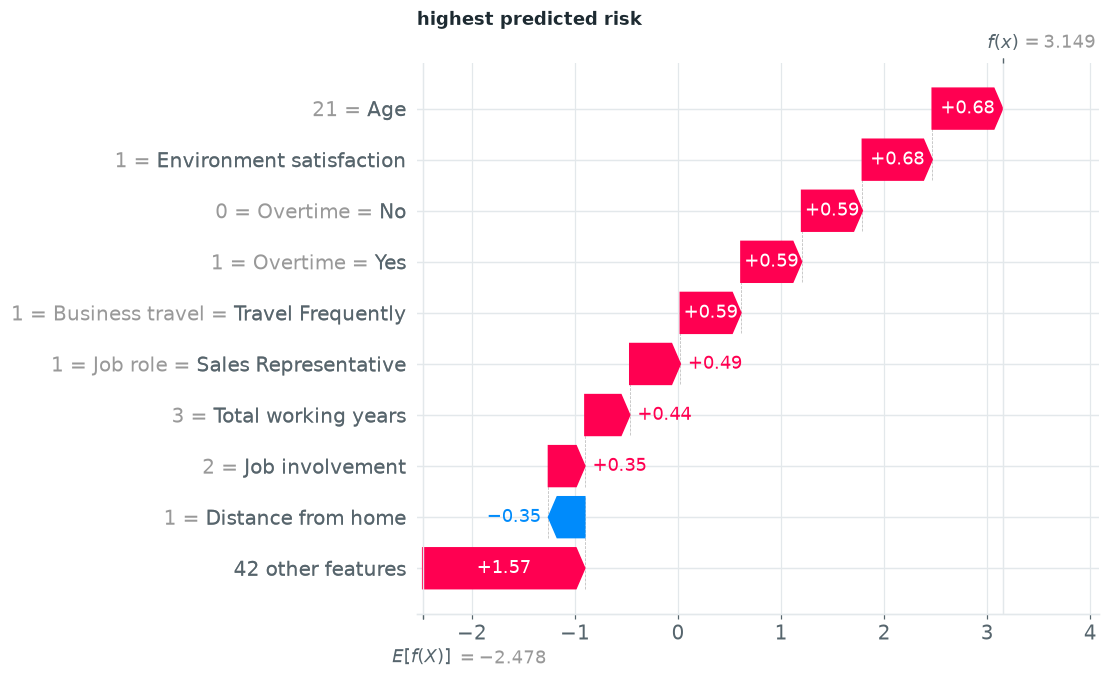

Employee #32 (lowest predicted risk): predicted 0%, actually stayed


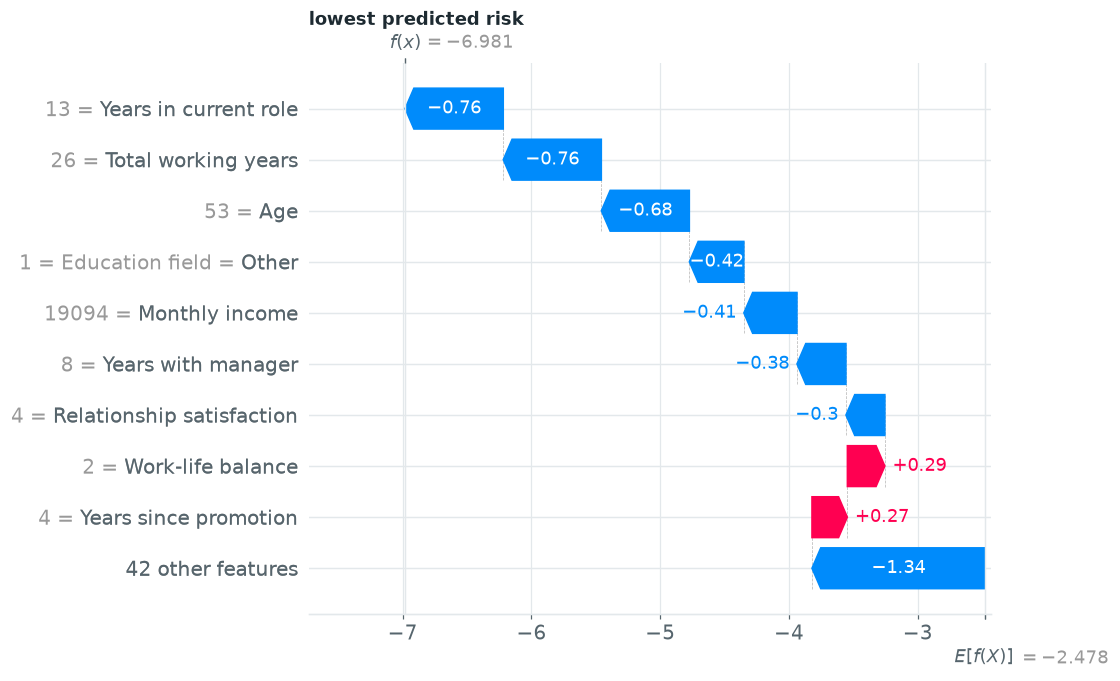

In [9]:
tp = b.test_predictions.set_index("row_id")
hi = tp["probability"].idxmax(); lo = tp["probability"].idxmin()
for rid, title in ((hi, "highest predicted risk"), (lo, "lowest predicted risk")):
    i = int(np.flatnonzero(ex.row_ids == rid)[0])
    print(f"Employee #{int(tp.loc[rid, 'EmployeeNumber'])} ({title}): predicted {tp.loc[rid, 'probability']:.0%}, actually "
          f"{'left' if tp.loc[rid, 'actual_left'] else 'stayed'}")
    shap.plots.waterfall(expl[i], max_display=10, show=False); plt.title(title, loc="left"); plt.show()

The waterfall starts at the average log-odds and adds each input's contribution. For the highest-risk employee several
risk factors stack up: overtime, a sales or lab role, low satisfaction and frequent travel. For the lowest-risk employee,
long experience, high satisfaction and no overtime pull in the other direction.

These are explanations of a **score**. They do not establish that changing an input would change the outcome, and the
person behind the record is fictional.

## Summary

* SHAP values are exact for this linear model and reconstruct every prediction.
* The model's main associations are overtime, promotion recency, job hopping, satisfaction and career stage.
* Permutation importance agrees on the leaders but gives correlated career features less credit. Explanations of
  correlated inputs should be read as a group.
* None of this is causal evidence.